Compare two eCMR models fitted to the same observations from the war-photo-recall experiment. Load the saved results, establish their common comparison basis, calculate AIC and save a comparison table.

## Parameters and setup

The tagged **parameters** cell contains the defaults for one run. Edit them here, or supply replacements through Quarto or Papermill. The following cell imports the tools and prepares paths from the resulting values.

Supply `fit_paths` explicitly for a new comparison: one pooled result per model, fitted to the same observations. This procedure does not implement participant-level or multi-dataset statistical reports.

Give independent jobs different `output_dir` values to keep their results separate. The discussion and saved results below describe the default example.

In [1]:
#| code-summary: "Set the parameters for this run"

fit_paths = {
    "Source-only eCMR": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "Broader eCMR": "data/fits/Dupertuys2026_eCMR_broad.json",
}
output_dir = "results/model_comparison"


In [2]:
#| code-summary: "Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "3f0607f5cbbc56afab915577a15ede81e1398c12"
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
    ])
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(fit_paths.values(), revision=revision)


In [3]:
#| code-summary: "Import packages"

if "data_names" in globals():
    raise ValueError(
        "This template compares explicit pooled fit_paths. The older data_names-based "
        "participant and multi-dataset report is not supported here. Use a project-specific "
        "comparison procedure for those reports."
    )

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 120})

# Resolve paths and derived settings after parameter overrides.
fit_paths = {label: Path(path) for label, path in fit_paths.items()}
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
from jaxcmr.helpers import save_figure
from jaxcmr.summarize import calculate_aic


## Establish what is being compared

Both supplied fits pool all 492 lists, exclude termination events from likelihood and use the
same no-stop policy. Each estimates ten parameters. They were prepared with the same current
JAXCMR source, 64-bit calculations, parameter bounds and search settings.

Both learn before context updating. Emotional encoding drift is fixed at 1; emotional recall
drift follows the fitted temporal recall drift. Emotional association strength is modulated
multiplicatively by primacy. Source-only eCMR fixes `phi_emot_modulates_temporal=False`;
broader eCMR sets it to `True`, adding emotional strength to temporal association learning.
`modulate_temporal_emotion_by_primacy=False` keeps that additional effect additive.

The legacy `emotion_drift_rate` parameter is absent. These are new fits under current equations,
not the historical ECMR3 solutions. A matching import path and parameter names do not guarantee
matching historical behavior; preserve the source fingerprint and parameter interpretation.

In [4]:
#| code-summary: "Read the fits and check their comparison basis"

records = {name: json.loads(path.read_text()) for name, path in fit_paths.items()}
comparison_basis = []
for name, record in records.items():
    if record["fits"]["subject"] != [-1] or len(record["fitness"]) != 1:
        raise ValueError(f"{name} is not the expected single pooled fit.")
    comparison_basis.append({
        "Model": name, "Data": record["data_tag"], "Selection": record["trial_query"],
        "Data SHA-256": record.get("data_sha256", "Not recorded"),
        "Source SHA-256": record.get("implementation", {}).get("source_sha256", "Not recorded"),
        "Likelihood": record["loss_function"],
        "Stopping policy": record["components"]["termination_policy_create_fn"],
    })
basis = pd.DataFrame(comparison_basis)
if any(basis[column].nunique() != 1 for column in basis.columns if column != "Model"):
    raise ValueError("These fits do not record a common data selection, likelihood and stopping rule.")
display(basis[["Model", "Data", "Selection"]])
print("Common objective:", basis["Likelihood"].iloc[0])
print("Common stopping policy:", basis["Stopping policy"].iloc[0])

,Model,Data,Selection
0,Source-only eCMR,Dupertuys2026,data['list_type'] > 0
1,Broader eCMR,Dupertuys2026,data['list_type'] > 0


Common objective: jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodLoss
Common stopping policy: jaxcmr.components.termination.NoStopTermination


## Calculate the comparison

For each pooled model, **AIC = 2 × free-parameter count + 2 × negative log likelihood**.
Lower values are preferred under this criterion. A parameter fixed before fitting is not counted
as free. Here the parameter counts are equal, so the AIC difference is twice the likelihood-score
difference. The comparison uses one pooled result per model, not 123 independently fitted estimates.

`jaxcmr.summarize.calculate_aic` performs the calculation. Its current interface expects
log-likelihood in `fitness`, whereas saved fitting results store **negative** log-likelihood.
Negate those scores in a separate input summary before calling it. The original fit records
retain their reported objectives. This convention differs from the module's AIC-weight helper,
which accepts negative log-likelihood directly.

,Model,Free parameters,Negative log likelihood,AIC,Delta AIC
0,Broader eCMR,10,7164.358,14348.716,0.000
1,Source-only eCMR,10,7169.426,14358.853,10.137


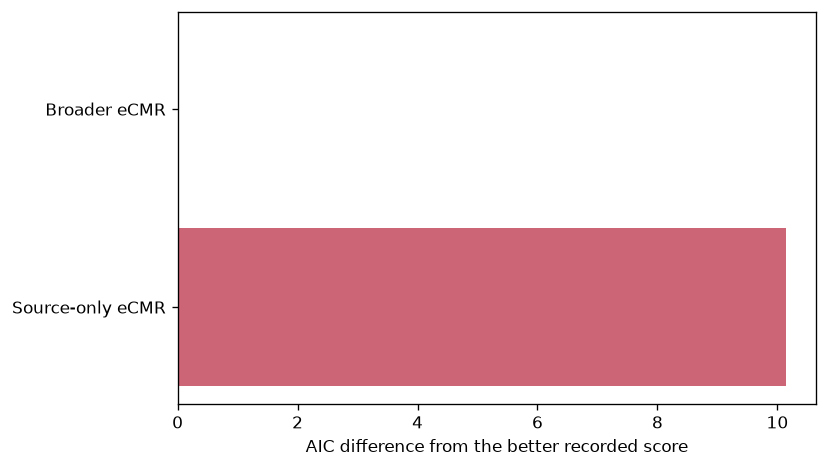

Model,Broader eCMR,Source-only eCMR
Seed,,
0,7164.358,7169.431
1,7164.407,7169.426


Same lower-NLL model in both seed sets: True


In [5]:
#| code-summary: "Calculate AIC and save the comparison"

# calculate_aic expects log-likelihood; FitResult.fitness stores NLL.
# Convert a separate summary, leaving the saved records untouched.
aic_inputs = [
    {"name": name, "free": record["free"], "fitness": -np.asarray(record["fitness"])}
    for name, record in records.items()
]
comparison = calculate_aic(aic_inputs)
comparison["Free parameters"] = comparison["Model"].map(lambda name: len(records[name]["free"]))
comparison["Negative log likelihood"] = comparison["Model"].map(lambda name: records[name]["fitness"][0])
comparison = comparison[["Model", "Free parameters", "Negative log likelihood", "AIC"]].reset_index(drop=True)
comparison["Delta AIC"] = comparison["AIC"] - comparison["AIC"].min()
comparison.to_csv(output_dir / "pooled_model_comparison.csv", index=False)
display(comparison.round(3))
fig, ax = plt.subplots()
ax.barh(comparison["Model"], comparison["Delta AIC"], color=["#4477AA", "#CC6677"])
ax.set_xlabel("AIC difference from the better recorded score")
ax.invert_yaxis()
save_figure(str(output_dir), "delta_aic", dpi=160)

# The supplied examples retain the two preparation searches for each model.
search_rows = [
    {"Model": name, "Seed": run["seed"], "NLL": run["nll"]}
    for name, record in records.items()
    for run in record.get("search_comparison", {}).get("runs", [])
]
if search_rows:
    search_table = pd.DataFrame(search_rows)
    display(search_table.pivot(index="Seed", columns="Model", values="NLL").round(3))
    winners = search_table.loc[search_table.groupby("Seed")["NLL"].idxmin(), ["Seed", "Model"]]
    print("Same lower-NLL model in both seed sets:", winners["Model"].nunique() == 1)


## Interpret and use your own fits

The selected source-only fit has negative log likelihood **7169.426** and the
broader fit **7164.358**. Both have ten free parameters, giving an AIC difference of
**10.137** in favor of broader eCMR. The same model has the lower objective in both seed sets.
The within-model NLL spreads are 0.005 for source-only eCMR and
0.049 for broader eCMR. These results describe the saved searches;
they do not establish a global optimum, parameter recovery or a conclusive theoretical result.

For another comparison, supply fits to the same observations with compatible likelihood and
stopping assumptions. Preserve their implementation identity and inspect search variation.
Explain the model difference and count the fitted parameters correctly. Small primacy scales
relative to the wide search bounds are recorded in each fit's boundary review; check those
values and parameter tradeoffs before interpreting individual estimates.

Do not turn pooled results into participant-level t-tests, winner proportions or confidence
intervals. This example uses AIC; it does not silently choose an observation count for AICc or
pool unrelated studies. The CSV table and figure are saved in `results/model_comparison/`.